# Algoritma Bellman-Ford: eksperimen waktu

**Mata kuliah:** Algoritma Komputasi, Magister Teknik Informatika, Universitas Hasanuddin
**Nama / NIM:** Muh Fauzi Ramadhan Nugraha / D082261017

Notebook pendamping `Bellman_Ford_Sederhana.ipynb`. Inti Bellman-Ford di bagian 2 **sama persis** dengan notebook sederhana dan tidak memakai pustaka. Pustaka hanya dipakai di luar inti: `numpy` dan `matplotlib` untuk statistik dan grafik, `scipy` sebagai pembanding, dan `time`/`random` bawaan Python untuk pengukuran dan pembangkitan graf.

Isi:
1. Lingkungan uji
2. Inti Bellman-Ford (tanpa pustaka)
3. Uji silang dengan scipy pada 1.000 graf acak kecil
4. Desain eksperimen
5. Pembangkit graf, mesin pengukuran, dan pelaksanaan (sekitar 13 menit)
6. Grafik, tabel hasil, dan kemiringan log-log

Jalankan dengan Restart and Run All. Seed tetap 2026. Hasil disimpan ke `hasil_eksperimen.csv`, `grafik_waktu_tiga_kasus.png`, dan `grafik_pembanding.png`.

## 1. Lingkungan uji

In [1]:
import platform, subprocess, sys, time, random
import numpy as np
import matplotlib.pyplot as plt

def spesifikasi_mesin():
    """Cetak spesifikasi komputer untuk dicantumkan di Bab 4 laporan."""
    cpu = platform.processor() or platform.machine()
    try:  # macOS memberi nama chip yang lebih jelas
        cpu = subprocess.check_output(["sysctl", "-n", "machdep.cpu.brand_string"], text=True).strip()
    except Exception:
        pass
    print("Sistem operasi :", platform.platform())
    print("Prosesor       :", cpu)
    print("Python         :", sys.version.split()[0])
    print("numpy          :", np.__version__)

spesifikasi_mesin()

Sistem operasi : macOS-27.0.1-arm64-arm-64bit-Mach-O
Prosesor       : Apple M2 Pro
Python         : 3.14.7
numpy          : 2.5.3


## 2. Inti Bellman-Ford

Sama dengan bagian 2 notebook sederhana.

In [2]:
INF = float("inf")


def inisialisasi(n, src):
    """Pseudocode baris 1-2: semua jarak INF kecuali sumber 0, semua pendahulu None."""
    dist = [INF] * n          # jarak sementara d[v]; INF = belum ada jalur yang diketahui
    pred = [None] * n         # pendahulu pi[v]; None = belum ada
    dist[src] = 0             # jarak sumber ke dirinya sendiri adalah 0
    return dist, pred


def relaksasi(u, v, w, dist, pred):
    """Pseudocode baris 5-6: perbarui d[v] bila lewat u lebih murah. Kembalikan True bila ada pembaruan."""
    # Sisi dari simpul yang belum terjangkau tidak boleh dipakai. Dengan INF float, INF + w tetap INF,
    # tetapi bila INF diganti bilangan besar biasa (mis. 10**9), jarak palsu bisa muncul.
    if dist[u] != INF and dist[u] + w < dist[v]:   # tanda '<' (bukan '<='): nilai sama bukan perbaikan
        dist[v] = dist[u] + w
        pred[v] = u
        return True
    return False


def satu_putaran(edges, dist, pred):
    """Pseudocode baris 4: periksa semua sisi sekali, sesuai urutan di edges.
    dist dan pred diubah di tempat, jadi pembaruan di tengah putaran langsung terlihat oleh sisi berikutnya."""
    ada_perubahan = False
    for u, v, w in edges:
        if relaksasi(u, v, w, dist, pred):
            ada_perubahan = True
    return ada_perubahan


def ada_siklus_negatif(edges, dist):
    """Pseudocode baris 7-8: putaran ke-|V|. Masih ada sisi yang bisa memperbarui d berarti ada siklus
    negatif yang terjangkau dari sumber. Fungsi ini tidak mengubah dist."""
    for u, v, w in edges:
        if dist[u] != INF and dist[u] + w < dist[v]:
            return True
    return False


def bellman_ford(n, edges, src, jejak=None, berhenti_dini=True):
    """Bellman-Ford: jarak terpendek dari satu sumber, bobot negatif diperbolehkan.

    Masukan : n     jumlah simpul (bernomor 0..n-1)
              edges daftar (u, v, w) untuk sisi berarah u -> v berbobot w
              src   simpul sumber
    Keluaran: (dist, pred, ada_siklus_negatif)
              dist[v] jarak terpendek (INF bila tak terjangkau)
              pred[v] simpul sebelum v pada jalur terpendek (None bila tidak ada)
    jejak   : opsional. Bila bukan None, diisi salinan dist: sekali setelah inisialisasi, lalu sekali di
              akhir tiap putaran. Dipakai untuk mencetak tabel jarak per putaran.
    berhenti_dini : bila True, perulangan berhenti begitu satu putaran tidak mengubah apa pun.
    """
    dist, pred = inisialisasi(n, src)                    # baris 1-2
    if jejak is not None:
        jejak.append(dist[:])
    for _ in range(n - 1):                               # baris 3: paling banyak |V| - 1 putaran
        ada_perubahan = satu_putaran(edges, dist, pred)  # baris 4-6
        if jejak is not None:
            jejak.append(dist[:])
        if berhenti_dini and not ada_perubahan:          # penghentian dini (aman: putaran berikutnya identik)
            break
    return dist, pred, ada_siklus_negatif(edges, dist)   # baris 7-9


def rekonstruksi_jalur(pred, src, target):
    """Susun jalur src -> target dengan menelusuri pred mundur. Kembalikan [] bila target tidak terjangkau."""
    jalur = []
    sekarang = target
    langkah = 0
    while sekarang is not None and langkah <= len(pred):   # batas langkah = pengaman bila pred berlingkaran
        jalur.append(sekarang)
        sekarang = pred[sekarang]
        langkah += 1
    if sekarang is not None:                               # berhenti karena batas langkah: pred berlingkaran
        return []
    jalur.reverse()
    return jalur if jalur and jalur[0] == src else []      # simpul tak terjangkau berujung bukan di src

## 3. Uji silang dengan scipy

Pembanding pustaka: `scipy.sparse.csgraph.bellman_ford` lewat adaptor `bf_pustaka`. Inti Bellman-Ford dijalankan pada 1.000 graf acak kecil (2 sampai 9 simpul, bobot −3 sampai 9, termasuk graf bersiklus negatif), lalu hasilnya dibandingkan dengan scipy: ada atau tidaknya siklus negatif, dan seluruh jarak bila tidak ada siklus. scipy hanya dipakai sebagai pembanding, bukan sebagai inti.

In [3]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import bellman_ford as scipy_bellman_ford, NegativeCycleError


def bf_pustaka(n, edges, src):
    """Pembanding: Bellman-Ford dari scipy. Mengembalikan (dist, ada_siklus_negatif).

    Sisi ganda (u, v) yang sama diambil bobot terkecilnya, sebab matriks sparse menjumlahkan duplikat.
    Waktu fungsi ini sudah termasuk pembentukan matriks sparse. Catat hal itu di laporan.
    """
    terkecil = {}
    for u, v, w in edges:
        if (u, v) not in terkecil or w < terkecil[(u, v)]:
            terkecil[(u, v)] = w
    if not terkecil:
        dist = [INF] * n
        dist[src] = 0
        return dist, False
    u, v, w = zip(*[(a, b, c) for (a, b), c in terkecil.items()])
    g = csr_matrix((w, (u, v)), shape=(n, n))
    try:
        d = scipy_bellman_ford(g, directed=True, indices=src)
    except NegativeCycleError:
        return None, True
    return [float(x) for x in d], False


def graf_uji_acak(rng):
    """Graf kecil acak untuk uji silang: 2-9 simpul, bobot -3 sampai 9, tanpa sisi ke diri sendiri."""
    n = rng.randint(2, 9)
    m = rng.randint(1, 2 * n)
    edges = []
    for _ in range(m):
        u = rng.randrange(n)
        v = rng.randrange(n)
        if u == v:
            v = (v + 1) % n
        edges.append((u, v, rng.randint(-3, 9)))
    return n, edges


def uji_silang(fungsi=None, jumlah=1000, seed=2026):
    """Bandingkan inti Bellman-Ford dengan scipy pada graf acak kecil.
    Yang dibandingkan: ada atau tidaknya siklus negatif, dan seluruh jarak bila tidak ada siklus negatif."""
    fungsi = fungsi or bellman_ford
    rng = random.Random(seed)
    beda = []
    n_siklus = 0
    for _ in range(jumlah):
        n, edges = graf_uji_acak(rng)
        dist, pred, neg = fungsi(n, edges, 0)
        d_ref, neg_ref = bf_pustaka(n, edges, 0)
        n_siklus += neg_ref
        if neg != neg_ref or (not neg_ref and list(dist) != d_ref):
            beda.append((n, edges, dist, neg, d_ref, neg_ref))
    print(f"graf diuji: {jumlah} (seed {seed}), bersiklus negatif: {n_siklus}, tanpa siklus negatif: {jumlah - n_siklus}")
    print(f"selisih dengan scipy: {len(beda)}")
    for n, edges, dist, neg, d_ref, neg_ref in beda[:3]:
        print("  contoh selisih:", n, edges, "| inti:", dist, neg, "| scipy:", d_ref, neg_ref)
    assert not beda, "Ada selisih dengan scipy, periksa contoh di atas."


uji_silang()

graf diuji: 1000 (seed 2026), bersiklus negatif: 105, tanpa siklus negatif: 895
selisih dengan scipy: 0


## 4. Desain eksperimen

**Desain eksperimen.** Syarat dosen: ≥5 ukuran masukan, ≥5 pengulangan (rata-rata dan simpangan baku), ≥1 pembanding, seed tetap, spesifikasi komputer.

| Keputusan | Pilihan | Alasan |
|---|---|---|
| Keluarga graf | tiga: rantai searah (terbaik), graf acak (rata-rata), rantai terbalik (terburuk); |E| = 4|V| pada semuanya | mewakili tiga kasus pada analisis Bab 3.4; |E| sebanding |V| membuat sumbu x tunggal dan kurva teori berupa fungsi |V| |
| Sumbu x | jumlah simpul |V| | kurva teori: terbaik dan rata-rata ≈ c·|V|, terburuk ≈ c·|V|² |
| Ukuran | terburuk 400 sampai 12.800; terbaik dan acak 1.000 sampai 300.000 (enam ukuran, kelipatan 2 atau 3) | terburuk 12.800 sudah sekitar 655 juta pemeriksaan sisi (puluhan detik per jalan); 300.000 simpul berarti 1,2 juta sisi, batas memori dan waktu membangun graf di Python |
| Versi diukur | dengan henti dini (utama); tanpa henti dini (ablasi) | memisahkan pengaruh henti dini dari struktur graf |
| Pengulangan | 5, graf berbeda tiap ulangan (seed 2026 + r); semua algoritma pada satu ulangan memakai graf yang sama | rata-rata dan simpangan baku mencakup variasi graf, bukan hanya derau pengukuran |
| Yang diukur | waktu dinding (`time.perf_counter`) pemanggilan algoritma saja; jumlah putaran sebagai hitungan operasi | pembangunan graf, matriks sparse, dan daftar tetangga ada di luar pengukuran |
| Pembanding | `scipy` Bellman-Ford (dibatasi |V| ≤ 30.000), BF tanpa henti dini, Dijkstra dengan `heapq` | pustaka teruji sebagai acuan benar dan waktu; Dijkstra menunjukkan biaya keumuman bobot negatif |
| Seed | 2026 | tetap, dicatat di laporan |

Setiap pengukuran sekaligus menguji kebenaran: hasil semua algoritma pada satu graf dibandingkan dan harus identik.

In [4]:
import csv
import json
import math

SEED = 2026


def ukur(fungsi, ulangan):
    """Jalankan fungsi tanpa argumen sebanyak `ulangan` kali.
    Kembalikan (rata-rata, simpangan baku) waktu dinding dalam detik."""
    waktu = []
    for _ in range(ulangan):
        t0 = time.perf_counter()
        fungsi()
        waktu.append(time.perf_counter() - t0)
    return float(np.mean(waktu)), float(np.std(waktu, ddof=1)) if ulangan > 1 else 0.0


def jalankan_eksperimen(ukuran, bangun, algoritma, ulangan, seed=SEED, graf_baru_tiap_ulangan=True):
    """Mesin pengukuran umum (tidak dipakai langsung; desain eksperimen ada di bagian 5).

    ukuran     daftar nilai x yang diuji (minimal 5)
    bangun     fungsi bangun(x, seed) -> (n, edges, src); pembangkit graf
    algoritma  dict {nama: fungsi(n, edges, src)}
    ulangan    banyak pengulangan per ukuran (minimal 5)
    graf_baru_tiap_ulangan  True: graf berbeda tiap ulangan (seed + r); False: graf yang sama diulang
    Waktu yang diukur hanya pemanggilan algoritma, tanpa waktu membangun graf.
    Mengembalikan dict {nama: {'mean': [...], 'std': [...]}} sejajar dengan `ukuran`.
    """
    hasil = {nama: {"mean": [], "std": []} for nama in algoritma}
    for x in ukuran:
        waktu = {nama: [] for nama in algoritma}
        for r in range(ulangan):
            n, edges, src = bangun(x, seed + (r if graf_baru_tiap_ulangan else 0))
            for nama, f in algoritma.items():
                t0 = time.perf_counter()
                f(n, edges, src)
                waktu[nama].append(time.perf_counter() - t0)
        for nama in algoritma:
            hasil[nama]["mean"].append(float(np.mean(waktu[nama])))
            hasil[nama]["std"].append(float(np.std(waktu[nama], ddof=1)) if ulangan > 1 else 0.0)
        print(f"x = {x}: selesai ({ulangan} ulangan)")
    return hasil


def skala_teori(f, ukuran, mean):
    """Kurva teoretis y = c * f(x), dengan c dipilih agar dekat dengan data
    (rata-rata geometrik rasio mean/f(x)). Pilihan konstanta ini disebut di laporan."""
    c = math.exp(np.mean([math.log(m / f(x)) for x, m in zip(ukuran, mean)]))
    return [c * f(x) for x in ukuran]


def simpan_csv(ukuran, hasil, nama_berkas="hasil_eksperimen.csv"):
    with open(nama_berkas, "w", newline="", encoding="utf8") as fh:
        w = csv.writer(fh)
        w.writerow(["ukuran", "algoritma", "mean_detik", "std_detik"])
        for nama, h in hasil.items():
            for x, m, s in zip(ukuran, h["mean"], h["std"]):
                w.writerow([x, nama, m, s])
    print("tersimpan:", nama_berkas)


def simpan_json_web(ukuran, hasil, teori=None, xlabel="ukuran masukan", nama_berkas="HASIL.json"):
    """Simpan dalam bentuk konstanta HASIL untuk halaman web belajar."""
    data = {"xlabel": xlabel, "ukuran": list(ukuran),
            "seri": [{"nama": n, "mean": h["mean"], "std": h["std"]} for n, h in hasil.items()]}
    if teori:
        data["teori"] = {"nama": teori["nama"], "y": teori["y"]}
    with open(nama_berkas, "w", encoding="utf8") as fh:
        json.dump(data, fh, indent=1)
    print("tersimpan:", nama_berkas)


def gambar_hasil(ukuran, hasil, teori=None, xlabel="ukuran masukan", simpan=None):
    """Grafik log-log: rata-rata dengan batang galat simpangan baku, plus kurva teoretis (opsional)."""
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for nama, h in hasil.items():
        mean = np.array(h["mean"])
        std = np.minimum(np.array(h["std"]), 0.9 * mean)  # batang bawah tidak boleh menyentuh nol pada skala log
        ax.errorbar(ukuran, mean, yerr=std, marker="o", capsize=3, label=nama)
    if teori:
        ax.plot(ukuran, teori["y"], "--", color="gray", label=teori["nama"])
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(xlabel + " (skala log)")
    ax.set_ylabel("waktu (detik, skala log)")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
    fig.tight_layout()
    if simpan:
        fig.savefig(simpan, dpi=200)
        print("tersimpan:", simpan)
    return fig

## 5. Pembangkit graf, mesin pengukuran, dan pelaksanaan

### 5a. Pembangkit graf

Tiga keluarga graf dan struktur turunan (matriks sparse, daftar tetangga) yang disiapkan di luar pengukuran waktu. Komentar pada kode menjelaskan kenapa tiap keluarga mewakili kasusnya.

In [5]:
"""Desain eksperimen Bellman-Ford (dipakai sebagai sel notebook di folder 6)."""
import heapq
import json
import random
import time

import numpy as np
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import bellman_ford as scipy_bf

SEED = 2026
ULANGAN = 5
RASIO_E = 4          # |E| = 4 |V| pada semua keluarga graf


def _lengkapi_sisi_berat(n, edges, ada, m, rng):
    """Tambahkan sisi maju (u < v, v - u >= 2) berbobot 10*(v-u)+1 sampai |E| = m.
    Bobot rantai paling besar 10 per sisi, jadi jalur rantai u -> v selalu <= 10*(v-u):
    sisi tambahan tidak pernah memperbaiki jarak, jadi tidak mengubah jalannya algoritma."""
    while len(edges) < m:
        u = rng.randrange(0, n - 2)
        v = rng.randrange(u + 2, n)
        if (u, v) in ada:
            continue
        ada.add((u, v))
        edges.append((u, v, 10 * (v - u) + 1))


def bangun_rantai(n, seed, terbalik):
    """Rantai 0 -> 1 -> ... -> n-1 berbobot acak 1..10 ditambah sisi berat.
    terbalik=False : sisi rantai diperiksa dari ujung sumber (kasus terbaik, 1 putaran berisi perubahan).
    terbalik=True  : sisi rantai diperiksa dari ujung jauh (kasus terburuk, n-1 putaran berisi perubahan)."""
    rng = random.Random(seed)
    rantai = [(i, i + 1, rng.randint(1, 10)) for i in range(n - 1)]
    if terbalik:
        rantai.reverse()
    edges = list(rantai)
    ada = {(u, v) for u, v, _ in edges}
    _lengkapi_sisi_berat(n, edges, ada, RASIO_E * n, rng)
    return edges


def bangun_acak(n, seed, geser):
    """Graf acak: pohon perentang acak dari sumber 0 (menjamin semua simpul terjangkau) ditambah sisi acak,
    |E| = 4|V|, urutan sisi diacak. Bobot dasar bulat 1..100.
    geser=True : bobot w(u,v) + p[u] - p[v] dengan p acak 0..50, sehingga ada bobot negatif tetapi tidak ada
                 siklus negatif (jumlah bobot sepanjang siklus tidak berubah oleh penggeseran ini).
    geser=False: bobot dasar tanpa geseran (tidak negatif), dipakai untuk perbandingan dengan Dijkstra."""
    rng = random.Random(seed)
    ada = set()
    edges = []
    for v in range(1, n):
        u = rng.randrange(0, v)
        ada.add((u, v))
        edges.append((u, v, rng.randint(1, 100)))
    while len(edges) < RASIO_E * n:
        u = rng.randrange(n)
        v = rng.randrange(n)
        if u == v or (u, v) in ada:
            continue
        ada.add((u, v))
        edges.append((u, v, rng.randint(1, 100)))
    if geser:
        p = [rng.randint(0, 50) for _ in range(n)]
        edges = [(u, v, w + p[u] - p[v]) for u, v, w in edges]
    rng.shuffle(edges)
    return edges


def paket(n, edges):
    """Struktur turunan yang disiapkan di luar pengukuran waktu: matriks sparse dan daftar tetangga."""
    u, v, w = zip(*edges)
    csr = csr_matrix((w, (u, v)), shape=(n, n))
    adj = [[] for _ in range(n)]
    for a, b, c in edges:
        adj[a].append((b, c))
    return {"n": n, "edges": edges, "csr": csr, "adj": adj}


def dijkstra(n, adj, src):
    """Dijkstra dengan heap biner (heapq) dan penghapusan malas; hanya benar untuk bobot tidak negatif."""
    INF = float("inf")
    dist = [INF] * n
    dist[src] = 0
    heap = [(0, src)]
    while heap:
        d, u = heapq.heappop(heap)
        if d > dist[u]:
            continue
        for v, w in adj[u]:
            nd = d + w
            if nd < dist[v]:
                dist[v] = nd
                heapq.heappush(heap, (nd, v))
    return dist

### 5b. Mesin pengukuran

`ukur_keluarga` menjalankan tiap algoritma pada tiap ukuran dan ulangan, membandingkan hasilnya, dan mencatat rata-rata, simpangan baku, serta jumlah putaran.

In [6]:
def waktu_panggil(f):
    t0 = time.perf_counter()
    hasil = f()
    return time.perf_counter() - t0, hasil


def hitung_putaran(n, edges, src=0):
    """Banyak putaran yang dijalankan Bellman-Ford dengan henti dini (tanpa putaran pendeteksi siklus)."""
    dist, pred = inisialisasi(n, src)
    k = 0
    for _ in range(n - 1):
        k += 1
        if not satu_putaran(edges, dist, pred):
            break
    return k


ALGO = {
    "BF milik sendiri": lambda pk: bellman_ford(pk["n"], pk["edges"], 0)[0],
    "BF tanpa henti dini": lambda pk: bellman_ford(pk["n"], pk["edges"], 0, berhenti_dini=False)[0],
    "BF scipy": lambda pk: scipy_bf(pk["csr"], directed=True, indices=0),
    "Dijkstra heapq": lambda pk: dijkstra(pk["n"], pk["adj"], 0),
}


def ukur_keluarga(keluarga, ukuran, bangun, nama_algo, batas=None, hitung_putaran_semua=True,
                  ulangan=ULANGAN, seed=SEED):
    """Ukur waktu dinding (time.perf_counter) tiap algoritma pada tiap ukuran.

    Tiap ulangan memakai graf berbeda (seed + r); semua algoritma pada ulangan yang sama memakai graf yang sama.
    Yang diukur hanya pemanggilan algoritma. Pembangunan graf, matriks sparse, dan daftar tetangga ada di luar
    pengukuran. Hasil semua algoritma pada tiap graf dibandingkan (harus identik), jadi satu pengukuran juga
    sekaligus satu uji kebenaran.
    batas: {nama_algo: ukuran terbesar yang diukur}.
    """
    batas = batas or {}
    baris = []
    for x in ukuran:
        wkt = {nm: [] for nm in nama_algo}
        putaran, m = [], 0
        for r in range(ulangan):
            edges = bangun(x, seed + r)
            m = len(edges)
            pk = paket(x, edges)
            acuan = None
            for nm in nama_algo:
                if x > batas.get(nm, float("inf")):
                    continue
                t, d = waktu_panggil(lambda: ALGO[nm](pk))
                wkt[nm].append(t)
                d = [float(v) for v in d]
                if acuan is None:
                    acuan = d
                else:
                    assert d == acuan, f"{nm} berbeda pada {keluarga}, x={x}, ulangan {r}"
            if hitung_putaran_semua or r == 0:
                putaran.append(hitung_putaran(x, edges))
        for nm in nama_algo:
            if not wkt[nm]:
                continue
            baris.append({"keluarga": keluarga, "algoritma": nm, "x": x, "E": m,
                          "mean": float(np.mean(wkt[nm])), "std": float(np.std(wkt[nm], ddof=1)),
                          "putaran": float(np.mean(putaran)), "n_ulangan": len(wkt[nm])})
        print(f"{keluarga:<10} x={x:<7} selesai ({ulangan} ulangan, putaran rata-rata {np.mean(putaran):.1f})")
    return baris

### 5c. Menjalankan eksperimen

Sel ini berjalan sekitar belasan menit pada mesin yang dicatat di bagian 1.

In [7]:
CEPAT = False   # True: ukuran sangat kecil, hanya untuk memeriksa bahwa sel berjalan

if CEPAT:
    U_TERBURUK = [50, 100, 200, 400, 800]
    U_LUAS = [100, 300, 1000, 3000, 10000]
    U_ABLASI = [50, 100, 200, 300, 400]
    BATAS_SCIPY = 3000
else:
    U_TERBURUK = [400, 800, 1600, 3200, 6400, 12800]
    U_LUAS = [1000, 3000, 10000, 30000, 100000, 300000]
    U_ABLASI = [500, 1000, 2000, 3000, 4000]
    BATAS_SCIPY = 30000      # scipy memakai waktu sebanding |V|*|E| pada semua graf, jadi dibatasi

HASIL = []
HASIL += ukur_keluarga("terburuk", U_TERBURUK, lambda x, s: bangun_rantai(x, s, True),
                       ["BF milik sendiri", "BF scipy"], hitung_putaran_semua=False)
HASIL += ukur_keluarga("terbaik", U_LUAS, lambda x, s: bangun_rantai(x, s, False),
                       ["BF milik sendiri", "BF scipy"], batas={"BF scipy": BATAS_SCIPY})
HASIL += ukur_keluarga("acak", U_LUAS, lambda x, s: bangun_acak(x, s, True),
                       ["BF milik sendiri", "BF scipy"], batas={"BF scipy": BATAS_SCIPY})
HASIL += ukur_keluarga("ablasi", U_ABLASI, lambda x, s: bangun_acak(x, s, True),
                       ["BF milik sendiri", "BF tanpa henti dini"])
HASIL += ukur_keluarga("dijkstra", U_LUAS, lambda x, s: bangun_acak(x, s, False),
                       ["BF milik sendiri", "Dijkstra heapq"])

terburuk   x=400     selesai (5 ulangan, putaran rata-rata 399.0)


terburuk   x=800     selesai (5 ulangan, putaran rata-rata 799.0)


terburuk   x=1600    selesai (5 ulangan, putaran rata-rata 1599.0)


terburuk   x=3200    selesai (5 ulangan, putaran rata-rata 3199.0)


terburuk   x=6400    selesai (5 ulangan, putaran rata-rata 6399.0)


...

ablasi     x=4000    selesai (5 ulangan, putaran rata-rata 10.4)
dijkstra   x=1000    selesai (5 ulangan, putaran rata-rata 8.2)
dijkstra   x=3000    selesai (5 ulangan, putaran rata-rata 9.6)


dijkstra   x=10000   selesai (5 ulangan, putaran rata-rata 11.4)


dijkstra   x=30000   selesai (5 ulangan, putaran rata-rata 12.8)


dijkstra   x=100000  selesai (5 ulangan, putaran rata-rata 13.8)


dijkstra   x=300000  selesai (5 ulangan, putaran rata-rata 16.0)


## 6. Grafik dibanding kurva teori

Grafik waktu terhadap ukuran masukan (skala log-log) bersama kurva kompleksitas teoretis, dengan batang galat = simpangan baku. Fungsi `skala_teori` memilih konstanta pengali secara otomatis. Tulis di laporan bagaimana konstanta itu dipilih.

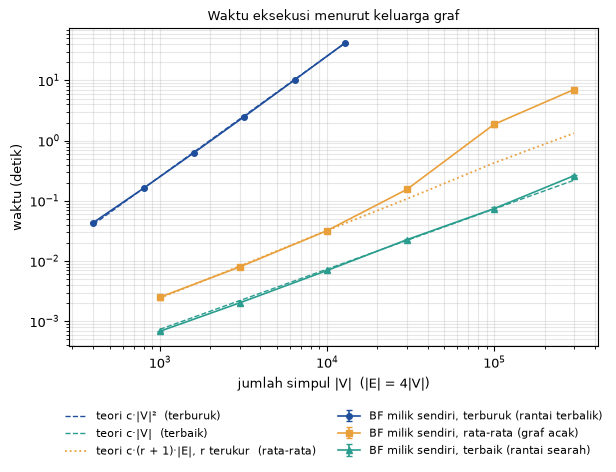

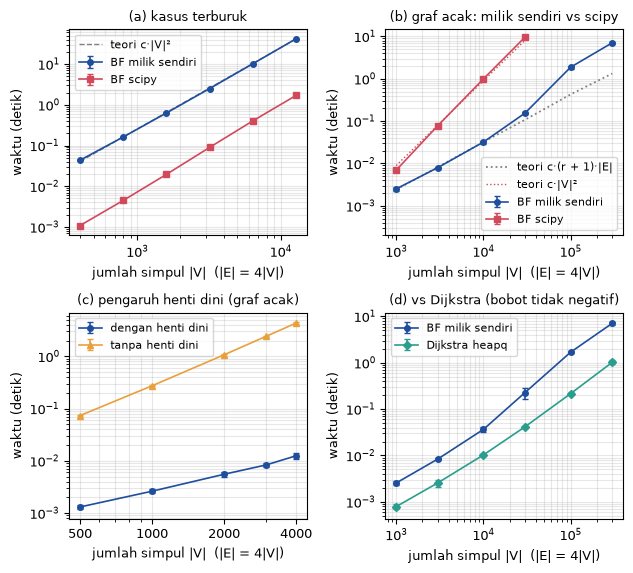

keluarga  algoritma                  |V|      |E|  putaran   rata-rata (s)     std (s)
terburuk  BF milik sendiri           400     1600    399.0        0.043610    0.000453
terburuk  BF scipy                   400     1600    399.0        0.001083    0.000035
terburuk  BF milik sendiri           800     3200    799.0        0.162437    0.000835
terburuk  BF scipy                   800     3200    799.0        0.004486    0.000210
terburuk  BF milik sendiri          1600     6400   1599.0        0.630781    0.003396
terburuk  BF scipy                  1600     6400   1599.0        0.019586    0.000434
terburuk  BF milik sendiri          3200    12800   3199.0        2.510903    0.010781
terburuk  BF scipy                  3200    12800   3199.0        0.090098    0.000882
terburuk  BF milik sendiri          6400    25600   6399.0       10.211523    0.123486
terburuk  BF scipy                  6400    25600   6399.0        0.403729    0.012999
terburuk  BF milik sendiri         12800   

In [8]:
import csv
import json

from matplotlib.ticker import NullFormatter, ScalarFormatter

plt.rcParams.update({"font.size": 9, "axes.titlesize": 9, "legend.fontsize": 8})
WARNA = {"BF milik sendiri": "#1f4e9c", "BF scipy": "#d1495b", "BF tanpa henti dini": "#e9a03b", "Dijkstra heapq": "#2a9d8f"}
MARKER = {"BF milik sendiri": "o", "BF scipy": "s", "BF tanpa henti dini": "^", "Dijkstra heapq": "D"}
WARNA_KEL = {"terburuk": "#1f4e9c", "acak": "#e9a03b", "terbaik": "#2a9d8f"}


def deret(keluarga, algoritma):
    b = [r for r in HASIL if r["keluarga"] == keluarga and r["algoritma"] == algoritma]
    return ([r["x"] for r in b], [r["mean"] for r in b], [r["std"] for r in b],
            [r["E"] for r in b], [r["putaran"] for r in b])


def kemiringan(x, y, terakhir=None):
    """Kemiringan regresi linear log(y) terhadap log(x)."""
    if terakhir:
        x, y = x[-terakhir:], y[-terakhir:]
    return float(np.polyfit(np.log(x), np.log(y), 1)[0])


def garis(ax, keluarga, algoritma, label=None, warna=None, marker=None):
    x, m, s, _, _ = deret(keluarga, algoritma)
    m = np.array(m)
    s = np.minimum(np.array(s), 0.9 * m)           # batang bawah tidak boleh menyentuh nol pada skala log
    ax.errorbar(x, m, yerr=s, color=warna or WARNA[algoritma], marker=marker or MARKER[algoritma], ms=4, lw=1.2,
                capsize=2, label=label or algoritma)
    return x, m


def teori_fungsi(ax, x, m, f, label, warna="gray", gaya="--"):
    """Kurva c * f(x); konstanta c dari rata-rata geometrik rasio mean / f(x) pada semua ukuran."""
    ax.plot(x, skala_teori(f, x, list(m)), gaya, color=warna, lw=1, label=label)


def teori_operasi(ax, keluarga, label, warna, awal=3):
    """Kurva c * (r + 1) * |E| dengan r terukur. c dari tiga ukuran terkecil, sebelum pengaruh memori terlihat."""
    x, m, _, e, r = deret(keluarga, "BF milik sendiri")
    ops = [(ri + 1) * ei for ri, ei in zip(r, e)]
    c = math.exp(np.mean([math.log(mi / oi) for mi, oi in list(zip(m, ops))[:awal]]))
    ax.plot(x, [c * o for o in ops], ":", color=warna, lw=1.3, label=label)


def hias(ax, judul, xlabel="jumlah simpul |V|  (|E| = 4|V|)"):
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(xlabel); ax.set_ylabel("waktu (detik)")
    ax.set_title(judul); ax.grid(True, which="both", alpha=0.3)


# ---- Gambar 1: tiga keluarga graf, BF milik sendiri, dengan kurva teoretis ----
fig, ax = plt.subplots(figsize=(6.4, 4.9))
for kel, nama, mk in [("terburuk", "terburuk (rantai terbalik)", "o"), ("acak", "rata-rata (graf acak)", "s"),
                      ("terbaik", "terbaik (rantai searah)", "^")]:
    garis(ax, kel, "BF milik sendiri", "BF milik sendiri, " + nama, warna=WARNA_KEL[kel], marker=mk)
x, m, *_ = deret("terburuk", "BF milik sendiri"); teori_fungsi(ax, x, m, lambda v: v ** 2, "teori c·|V|²  (terburuk)", WARNA_KEL["terburuk"])
x, m, *_ = deret("terbaik", "BF milik sendiri"); teori_fungsi(ax, x, m, lambda v: v, "teori c·|V|  (terbaik)", WARNA_KEL["terbaik"])
teori_operasi(ax, "acak", "teori c·(r + 1)·|E|, r terukur  (rata-rata)", WARNA_KEL["acak"])
hias(ax, "Waktu eksekusi menurut keluarga graf")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False)
fig.tight_layout(); fig.savefig("grafik_waktu_tiga_kasus.png", dpi=300); plt.show()

# ---- Gambar 2: pembanding ----
fig, axs = plt.subplots(2, 2, figsize=(6.4, 5.8))
ax = axs[0, 0]
x, m = garis(ax, "terburuk", "BF milik sendiri"); teori_fungsi(ax, x, m, lambda v: v ** 2, "teori c·|V|²")
garis(ax, "terburuk", "BF scipy"); hias(ax, "(a) kasus terburuk"); ax.legend()
ax = axs[0, 1]
garis(ax, "acak", "BF milik sendiri"); teori_operasi(ax, "acak", "teori c·(r + 1)·|E|", "gray")
x2, m2 = garis(ax, "acak", "BF scipy"); teori_fungsi(ax, x2, m2, lambda v: v ** 2, "teori c·|V|²", warna="#d1495b", gaya=":")
hias(ax, "(b) graf acak: milik sendiri vs scipy"); ax.set_ylim(bottom=2e-4); ax.legend(loc="lower right")
ax = axs[1, 0]
garis(ax, "ablasi", "BF milik sendiri", "dengan henti dini"); garis(ax, "ablasi", "BF tanpa henti dini", "tanpa henti dini")
hias(ax, "(c) pengaruh henti dini (graf acak)"); ax.legend()
ax.set_xticks([500, 1000, 2000, 4000]); ax.xaxis.set_major_formatter(ScalarFormatter()); ax.xaxis.set_minor_formatter(NullFormatter())
ax = axs[1, 1]
garis(ax, "dijkstra", "BF milik sendiri"); garis(ax, "dijkstra", "Dijkstra heapq")
hias(ax, "(d) vs Dijkstra (bobot tidak negatif)"); ax.legend()
fig.tight_layout(); fig.savefig("grafik_pembanding.png", dpi=300); plt.show()

# ---- Tabel hasil, waktu per pemeriksaan sisi, dan kemiringan log-log ----
print(f"{'keluarga':<10}{'algoritma':<22}{'|V|':>8}{'|E|':>9}{'putaran':>9}{'rata-rata (s)':>16}{'std (s)':>12}")
for r in HASIL:
    print(f"{r['keluarga']:<10}{r['algoritma']:<22}{r['x']:>8}{r['E']:>9}{r['putaran']:>9.1f}{r['mean']:>16.6f}{r['std']:>12.6f}")

print("\nWaktu per pemeriksaan sisi, BF milik sendiri (nanodetik) = waktu / ((r + 1) * |E|):")
for kel in ["terburuk", "terbaik", "acak"]:
    x, m, s, e, r = deret(kel, "BF milik sendiri")
    print(f"  {kel:<9}" + "  ".join(f"{xi}: {mi / ((ri + 1) * ei) * 1e9:.0f}" for xi, mi, ei, ri in zip(x, m, e, r)))

print("\nKemiringan regresi log-log (waktu terhadap |V|):")
print(f"{'keluarga':<10}{'algoritma':<22}{'semua titik':>13}{'3 terbesar':>12}")
for kel in ["terburuk", "terbaik", "acak", "ablasi", "dijkstra"]:
    for alg in dict.fromkeys(r["algoritma"] for r in HASIL if r["keluarga"] == kel):
        x, m, *_ = deret(kel, alg)
        print(f"{kel:<10}{alg:<22}{kemiringan(x, m):>13.2f}{kemiringan(x, m, 3):>12.2f}")

with open("hasil_eksperimen.csv", "w", newline="", encoding="utf8") as fh:
    w = csv.DictWriter(fh, fieldnames=list(HASIL[0]))
    w.writeheader(); w.writerows(HASIL)
print("\ntersimpan: hasil_eksperimen.csv, grafik_waktu_tiga_kasus.png, grafik_pembanding.png")